# Insurance cross selling with XGBoost

- Goal: The objective is to predict which customers respond positively to an automobile insurance offer.
- Dataset:  The dataset is about an Insurance company that has provided Health Insurance to its customers. Now we need build a model to predict whether the policyholders (customers) from past year will also be interested in Vehicle Insurance provided by the company

## Installing required libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline

import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier

In [2]:
import warnings
warnings.filterwarnings("ignore")

## Understanding the dataset

### Reading the datasets

In [3]:
## Reading the datasets
train = pd.read_csv("./dataset/train.csv")
test = pd.read_csv("./dataset/test.csv")

In [4]:
## checking the first five rows of data
train.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,0,Male,21,1,35.0,0,1-2 Year,Yes,65101.0,124.0,187,0
1,1,Male,43,1,28.0,0,> 2 Years,Yes,58911.0,26.0,288,1
2,2,Female,25,1,14.0,1,< 1 Year,No,38043.0,152.0,254,0
3,3,Female,35,1,1.0,0,1-2 Year,Yes,2630.0,156.0,76,0
4,4,Female,36,1,15.0,1,1-2 Year,No,31951.0,152.0,294,0


### Basic description of data

In [5]:
## shape of data
train.shape

(11504798, 12)

In [6]:
## datatypes of columns
train.dtypes

id                        int64
Gender                   object
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age              object
Vehicle_Damage           object
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object

In [7]:
## checking if there any duplicate rows
train[train.duplicated] ## gives duplicate rows
len(train[train.duplicated(["id"])]) ## get the number of duplicate riows by id

0

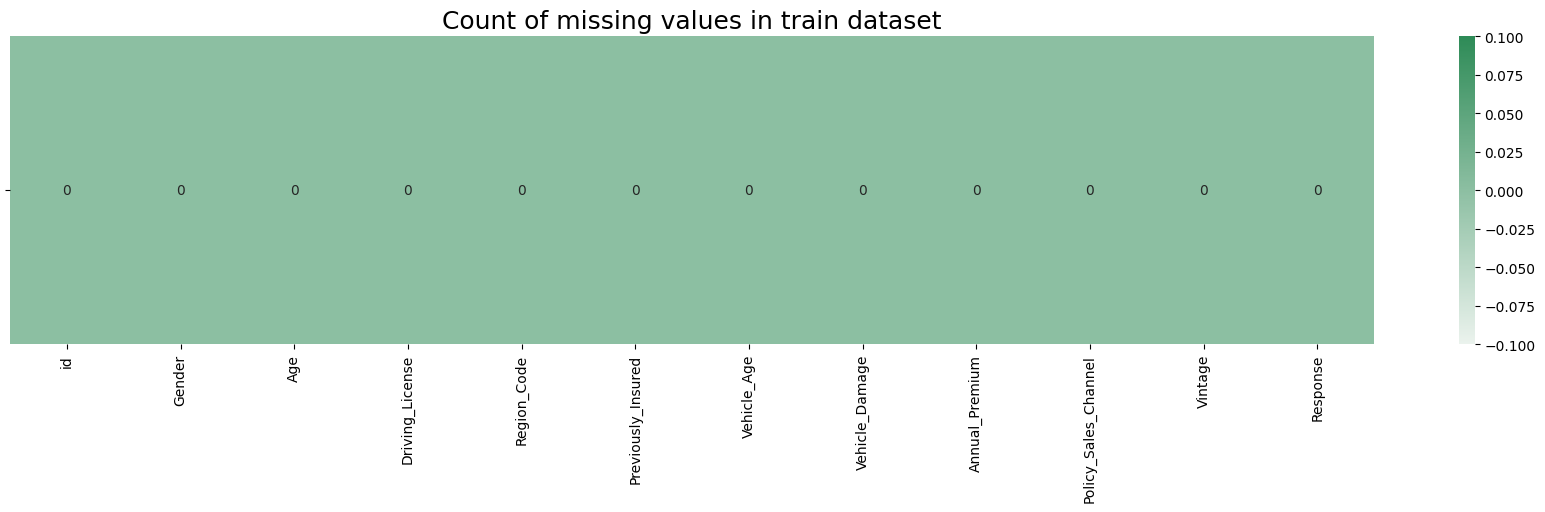

In [8]:
## checking for missing values
train.isna().sum() ## gives total missing values in all the columns

## creating a color map
cmap = sns.light_palette("seagreen", as_cmap=True)

## creating heatmap for missing values in dataset
plt.figure(figsize=(max(22, 11), 4))

sns.heatmap(
    train.isna().sum().to_frame(name="").T,
    cmap= cmap,
    annot= True,
    fmt= '0.0f',
).set_title('Count of missing values in train dataset', fontsize=18)

plt.show()

### Checking number of unique values in categorical columns

In [9]:
cat_cols = [col for col in train.columns if train[col].dtype == 'object'] 
print(cat_cols)

['Gender', 'Vehicle_Age', 'Vehicle_Damage']


In [10]:
train.Gender.value_counts() ## gives total count of the all the unique values

print("Percentage of unique values in categoricals columns")
print("-" *30)
for col in cat_cols:
    print("\n")
    print(train[col].value_counts(normalize=True))
    print("#"*30)

Percentage of unique values in categoricals columns
------------------------------


Gender
Male      0.541351
Female    0.458649
Name: proportion, dtype: float64
##############################


Vehicle_Age
1-2 Year     0.520016
< 1 Year     0.438438
> 2 Years    0.041546
Name: proportion, dtype: float64
##############################


Vehicle_Damage
Yes    0.50268
No     0.49732
Name: proportion, dtype: float64
##############################


### Age

In [11]:
## Descriptive statistics
train.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,1.150480e+07,1.150480e+07,1.150480e+07,1.150480e+07,1.150480e+07,1.150480e+07,1.150480e+07,1.150480e+07,1.150480e+07
mean,5.752398e+06,3.838356e+01,9.980220e-01,2.641869e+01,4.629966e-01,3.046137e+04,1.124254e+02,1.638977e+02,1.229973e-01
std,3.321149e+06,1.499346e+01,4.443120e-02,1.299159e+01,4.986289e-01,1.645475e+04,5.403571e+01,7.997953e+01,3.284341e-01
min,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,2.630000e+03,1.000000e+00,1.000000e+01,0.000000e+00
25%,2.876199e+06,2.400000e+01,1.000000e+00,1.500000e+01,0.000000e+00,2.527700e+04,2.900000e+01,9.900000e+01,0.000000e+00
50%,5.752398e+06,3.600000e+01,1.000000e+00,2.800000e+01,0.000000e+00,3.182400e+04,1.510000e+02,1.660000e+02,0.000000e+00
75%,8.628598e+06,4.900000e+01,1.000000e+00,3.500000e+01,1.000000e+00,3.945100e+04,1.520000e+02,2.320000e+02,0.000000e+00
max,1.150480e+07,8.500000e+01,1.000000e+00,5.200000e+01,1.000000e+00,5.401650e+05,1.630000e+02,2.990000e+02,1.000000e+00


In [12]:
train.Age.max(axis=0)

np.int64(85)

In [13]:
train[train.Age == train.Age.max(axis=0)]

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
285234,285234,Female,85,1,28.0,1,1-2 Year,No,51687.0,122.0,296,0
512474,512474,Female,85,1,28.0,1,1-2 Year,No,53587.0,26.0,204,0
2239899,2239899,Female,85,1,28.0,0,1-2 Year,Yes,38789.0,124.0,289,0
2418103,2418103,Female,85,1,28.0,1,1-2 Year,No,41080.0,124.0,129,0
6108542,6108542,Female,85,1,28.0,0,1-2 Year,Yes,44599.0,26.0,52,0
6977668,6977668,Female,85,1,28.0,1,1-2 Year,No,27057.0,124.0,294,0
7072281,7072281,Female,85,1,28.0,0,1-2 Year,Yes,58699.0,26.0,205,0
8677721,8677721,Female,85,1,28.0,0,1-2 Year,Yes,24556.0,26.0,197,0
9873529,9873529,Female,85,0,28.0,0,1-2 Year,Yes,47643.0,26.0,272,0


In [14]:
train[train.Age == train.Age.min(axis=0)].head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
17,17,Female,20,1,50.0,1,< 1 Year,No,36389.0,160.0,242,0
33,33,Female,20,1,8.0,0,< 1 Year,Yes,48752.0,160.0,151,0
242,242,Female,20,1,46.0,1,< 1 Year,No,36090.0,160.0,54,0
269,269,Male,20,1,44.0,0,< 1 Year,Yes,2630.0,160.0,100,0
338,338,Female,20,1,50.0,0,< 1 Year,Yes,28783.0,160.0,199,0


### Driving license

In [15]:
train.Driving_License.value_counts(normalize=True)

Driving_License
1    0.998022
0    0.001978
Name: proportion, dtype: float64

In [16]:
## Male v/s Female distribution
grouped = train.groupby('Driving_License')['Gender']
grouped.value_counts(normalize=True).reset_index()

,Driving_License,Gender,proportion
0,0,Male,0.750670
1,0,Female,0.249330
2,1,Male,0.540936
3,1,Female,0.459064


### Region code

In [17]:
train.Region_Code.nunique()

54

### Previously Issued

In [18]:
train.Previously_Insured.nunique()

2

In [19]:
train.Previously_Insured.value_counts(normalize=True)

Previously_Insured
0    0.537003
1    0.462997
Name: proportion, dtype: float64

In [20]:
grouped = train.groupby('Previously_Insured')['Gender']
grouped.value_counts(normalize=True).reset_index()

,Previously_Insured,Gender,proportion
0,0,Male,0.581888
1,0,Female,0.418112
2,1,Female,0.505666
3,1,Male,0.494334


### Vehicle Age

In [21]:
train.Vehicle_Age.value_counts(normalize=True)

Vehicle_Age
1-2 Year     0.520016
< 1 Year     0.438438
> 2 Years    0.041546
Name: proportion, dtype: float64

In [22]:
grouped = train.groupby('Vehicle_Age')['Driving_License']
grouped.value_counts(normalize=True)

Vehicle_Age  Driving_License
1-2 Year     1                  0.996469
             0                  0.003531
< 1 Year     1                  0.999994
             0                  0.000006
> 2 Years    1                  0.996657
             0                  0.003343
Name: proportion, dtype: float64

### Initial findings:

- <span style='color:cyan'>  To be added </span>